# Task 4 · Email Spam Detection with Machine Learning

Build a classifier that labels a message as **spam** or **ham** (legitimate). The table is the UCI SMS Spam Collection, the standard public stand-in for this task: one text message per row, already marked spam or ham.


## 1. Setup


In [1]:
%matplotlib inline
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

DATA_PATH = Path("data") / "sms.tsv"


## 2. Load and class balance

The file has no header. The first column is the label and the second is the message text.


In [2]:
raw = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "message"])
print("Shape:", raw.shape)
print("Missing values:", int(raw.isnull().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print()
counts = raw["label"].value_counts()
share = raw["label"].value_counts(normalize=True).mul(100)
balance = pd.DataFrame({"count": counts, "percent": share.round(2)})
balance


Shape: (5572, 2)
Missing values: 0
Duplicate rows: 403



,count,percent
label,,
ham,4825,86.59
spam,747,13.41


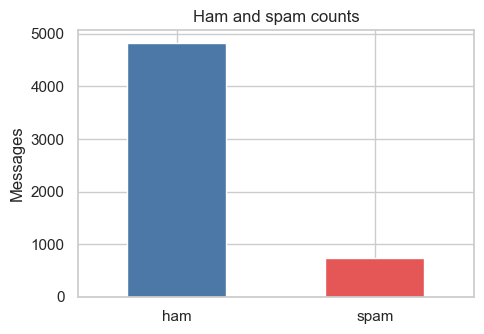

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.5))
balance["count"].plot.bar(ax=ax, color=["#4C78A8", "#E45756"], rot=0)
ax.set_xlabel("")
ax.set_ylabel("Messages")
ax.set_title("Ham and spam counts")
fig.tight_layout()
plt.show()


The file has **5,572 messages** and no missing text. **4,825 (86.6%)** are ham and **747 (13.4%)** are spam. Accuracy will look high for a classifier that rarely says spam, so the spam row of the classification report matters more than the overall accuracy.

**403 rows are exact duplicates.** They are dropped before the split so the same message cannot sit in both the training set and the test set. After that, 5,169 messages remain.


In [4]:
df = raw.drop_duplicates().reset_index(drop=True)
print("Rows after dropping duplicates:", len(df))
print(df["label"].value_counts())
df.head()


Rows after dropping duplicates: 5169
label
ham     4516
spam     653
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 3. Text preprocessing

Each message goes through the same steps:

1. Lowercase, so `Free` and `free` match.
2. HTML leftovers such as `&lt;` and `&gt;` are removed. This corpus uses them as placeholders, and they would otherwise show up as the tokens `lt` and `gt`.
3. Punctuation and digits are replaced with spaces. The remaining tokens are letters only.
4. English stopwords (`the`, `and`, `you`) are dropped.
5. Porter stemming folds `calling`, `called`, and `calls` into one token.

Stemming is rougher than lemmatization and does not need a part-of-speech tag. It is enough here, where the goal is a smaller shared vocabulary for spam phrases.


In [5]:
stemmer = PorterStemmer()
stopword_set = set(stopwords.words("english"))


def preprocess(text):
    text = str(text).lower()
    text = text.replace("&lt;", " ").replace("&gt;", " ").replace("&amp;", " ")
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [
        stemmer.stem(token)
        for token in text.split()
        if token not in stopword_set and len(token) > 1
    ]
    return " ".join(tokens)


df["clean_message"] = df["message"].map(preprocess)
df[["label", "message", "clean_message"]].head(6)


,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go jurong point crazi avail bugi great world la buffet cine got amor wat
1,ham,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entri wkli comp win fa cup final tkt st may text fa receiv entri question std txt rate appli
3,ham,U dun say so early hor... U c already then say...,dun say earli hor alreadi say
4,ham,"Nah I don't think he goes to usf, he lives around here though",nah think goe usf live around though
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...,freemsg hey darl week word back like fun still tb ok xxx std chg send rcv


## 4. TF-IDF

**TF-IDF** turns a message into a row of word scores.

- **Term frequency** is how often the word appears in that message.
- **Inverse document frequency** is high when the word is rare across messages, and low when the word shows up almost everywhere.

A word such as `free` or `claim` that appears in a spam message and in few ham messages gets a high score. A word that appears in both classes gets pushed down. The vectorizer learns the vocabulary from the training messages only, then applies the same vocabulary to the test messages.


## 5. Train/test split and models

The split is 80/20 and stratified, so the test set keeps the same spam share as the full table (`random_state=42`).

Multinomial naive Bayes is the usual first model for word counts and TF-IDF: it treats each token score as evidence for spam or ham. Logistic regression is the second model. It learns one weight per token and can down-weight a word that naive Bayes would over-trust.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_message"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"],
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Spam share in test:", round((y_test.eq("spam")).mean(), 3))

vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("Vocabulary size:", len(vectorizer.vocabulary_))

models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}
predictions = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    predictions[name] = model.predict(X_test_tfidf)


Training rows: 4135
Test rows: 1034
Spam share in test: 0.127
Vocabulary size: 5592


## 6. Evaluation

Labels in the confusion matrix are ordered ham, then spam. Precision, recall, and F1 are reported for both classes. The spam row is the one that says how the filter behaves.


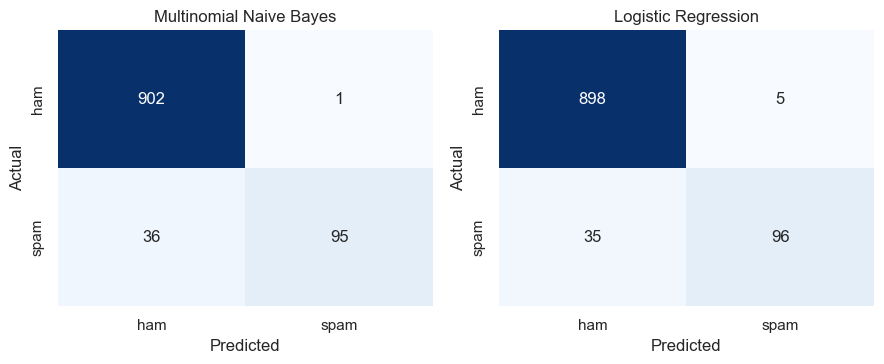

In [7]:
labels = ["ham", "spam"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, models):
    matrix = confusion_matrix(y_test, predictions[name], labels=labels)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.tight_layout()
plt.show()


In [8]:
for name in models:
    print("=" * 60)
    print(name)
    print("Accuracy:", round(accuracy_score(y_test, predictions[name]), 3))
    print()
    print(classification_report(y_test, predictions[name], digits=3))


Multinomial Naive Bayes
Accuracy: 0.964

              precision    recall  f1-score   support

         ham      0.962     0.999     0.980       903
        spam      0.990     0.725     0.837       131

    accuracy                          0.964      1034
   macro avg      0.976     0.862     0.908      1034
weighted avg      0.965     0.964     0.962      1034

Logistic Regression
Accuracy: 0.961

              precision    recall  f1-score   support

         ham      0.962     0.994     0.978       903
        spam      0.950     0.733     0.828       131

    accuracy                          0.961      1034
   macro avg      0.956     0.864     0.903      1034
weighted avg      0.961     0.961     0.959      1034



## 7. Why recall matters for spam

Accuracy on this test set is about **96%** for both models (0.964 for naive Bayes, 0.961 for logistic regression). That number is flattering because about **87%** of messages are ham. A filter that called everything ham would already be near that, and it would catch no spam.

Recall on the spam class is the share of real spam that was stopped. Naive Bayes catches **95 of 131** spam messages and misses **36** (recall 0.725). Logistic regression catches **96** and misses **35** (recall 0.733). Those misses still arrive. That is the failure a spam filter is there to prevent.

Precision is the other side. Of the messages marked spam, how many really are spam. Naive Bayes marks **1** ham message as spam (spam precision **0.990**). Logistic regression marks **5** (precision **0.950**). Hiding a real message is a cost, and on this split it is a smaller cost than the spam that still gets through. Recall is the metric that shows both filters still miss about one spam message in four, which the accuracy figure hides.


## 8. Word clouds

Each cloud is built from the cleaned training-and-test text of that class, after stopword removal and stemming. Size follows how often the token appears.


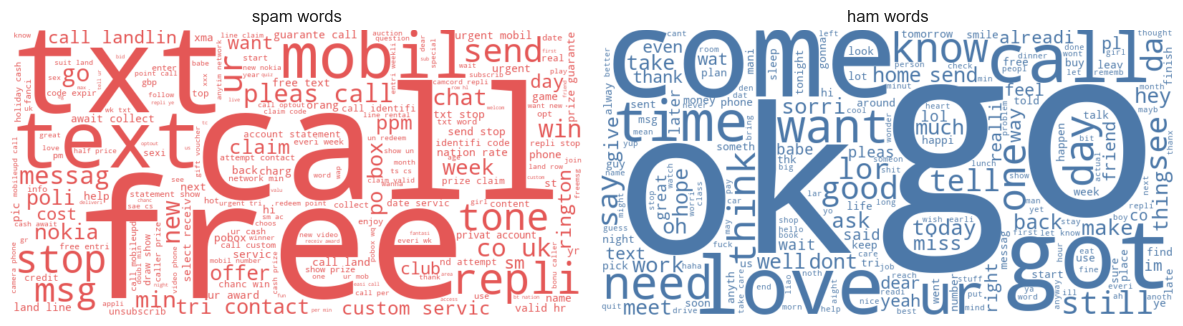

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, label, color in zip(axes, ["spam", "ham"], ["#E45756", "#4C78A8"]):
    text = " ".join(df.loc[df["label"].eq(label), "clean_message"])
    cloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        colormap="Reds" if label == "spam" else "Blues",
        color_func=lambda *args, **kwargs: color,
    ).generate(text)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(f"{label} words")
    ax.axis("off")
fig.tight_layout()
plt.show()


The spam cloud is offer language and instructions: `call`, `free`, `txt`, `text`, `claim`, `prize`, `mobil`. The ham cloud is ordinary conversation: `go`, `get`, `come`, `ok`, `know`, `love`, `got`, `time`. `call` appears in both, which is why a single word is not a rule. Spam `call` sits next to `free`, `claim`, and `prize`. Ham `call` sits next to everyday verbs.


## 9. Best model

**Multinomial naive Bayes is the better spam filter on this split.**

| Model | Accuracy | Spam precision | Spam recall | Spam F1 |
| --- | ---: | ---: | ---: | ---: |
| Multinomial naive Bayes | 0.964 | 0.990 | 0.725 | 0.837 |
| Logistic regression | 0.961 | 0.950 | 0.733 | 0.828 |

Logistic regression catches one more spam message. Naive Bayes marks one ham message as spam, against five for logistic regression, and its spam F1 is higher (0.837 against 0.828). Logistic regression is the model to open up when the question is which tokens push a message toward spam. For the yes-or-no decision, naive Bayes is the one to keep. The recall gap is still the limit: about one in four spam messages gets through.
